# Where temperature changes the algorithm an LLM writes

*Artifact `art_MZAfDPVhM6Ui` (iteration 7, claim T) · Qwen/Qwen3-8B, revision `b968826d`, bf16, thinking off · verdict **PARTIAL***

**The question.** Is sampling temperature the "creativity knob" of an LLM? The experiment tests this on coding tasks.
- **Mixed units.** On three units Qwen3-8B writes one of two known algorithms:
  - **B3**, minimum spanning tree: Kruskal 0.80 vs Prim with a heap 0.19.
  - **A3**, trapped rain water: prefix/suffix arrays vs two pointers.
  - **B6**, valid anagram: sort vs a 26-slot count array.
- **Collapsed tasks.** On four tasks it writes only one algorithm: T1 grid path → BFS, T2 shortest path → Dijkstra, T10 components → union-find, T03 k-th smallest → full sort.

**What the full pipeline found** (`method.py`, about 0.75 GPU-hours on an RTX 4090):
1. **Where the algorithm is decided (Test 1, passes on 3 of 3 units).** Prefix resampling with Bayesian change points finds a one-token fork right after the canonical opening (|O|+1).
   - On B3 the fork is the word after `    # `: ` Kr` → Kruskal (100%), ` Prim` → Prim (97%).
   - H(algorithm | fork class) = 0.050 / 0.153 / 0.189 bits on B3 / A3 / B6.
2. **Temperature predictions (Test 2, passes on B3 only).** A prediction function takes the teacher-forced logits along the opening and at the fork, times P(algorithm | fork token). It was sha256-committed before any temperature sample.
   - It was tested on a same-seed sweep: the same 50 uniform streams in all 8 cells (T 0.3/0.7/1.0/1.3 × top-p 1 / top-k 10).
   - Lowering T collapses B3 onto Kruskal, as predicted (McNemar 17:0).
   - Raising T above 1 adds nothing.
   - Top-k 10 is token-identical to top-p 1 (600/600).
3. **Collapsed tasks (Test 3, passes on 4 of 4).** Fork margins of 4.9-17 nats put the alternatives out of temperature's reach.
4. **Ideas vs phrasings.** Temperature only reweights the same 2-3 known ideas; only the phrasings multiply. No new correct algorithm appeared in 2,290 programs.

**What this notebook runs.** The GPU stages (Qwen3-8B generation and teacher forcing, on a ≥ 20 GB GPU) cannot run in Colab within minutes. So the notebook keeps `method.py`'s stage map and runs the pipeline's **CPU-side code, copied unchanged from `src/`**, on `mini_demo_data.json`.
- **Data:** 100 recorded B3 programs from the same-seed sweep (top-p 1; T 0.3/0.7/1.0/1.3; templates W1-W5; slots 20-24), plus the committed (COMMIT #2) numbers that score them.
- **Code:**
  - `cfg7.py` for the CRN seeds and `replay.py` for the sampler;
  - `predict.py`, the prediction function, with its unit tests and Test 3;
  - `predictions7.py` for the Test 1 entropy;
  - `analysis_T.py` for the Test 2 scoring and the ideas-vs-phrasings table.

Every adaptation in the code is marked `DEMO CHANGE` or `notebook`.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (method.py logs with it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- import block of method.py (verbatim) ----
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# ---- imports of the src/ modules used below (cfg7, replay, predict, forks, predictions7, analysis_T) ----
import ast
import hashlib
import json
import math
import re
import types
from collections import Counter
from typing import Any

import numpy as np
from scipy.stats import binom

# ---- notebook addition: plotting ----
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-7/experiment-35/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# Until this notebook's files are pushed, GITHUB_DATA_URL can still serve an older mini_demo_data.json with another
# layout (no "datasets" list); the local copy is used then.
if "datasets" not in data:
    print("the GitHub copy has another layout; using the local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
META = data["metadata"]
EX = data["datasets"][0]["examples"]
print(META["method_name"], "|", META["model"])
print("verdict:", META["verdict"]["verdict"], META["verdict"]["passes"])
print(f"{len(EX)} examples from dataset '{data['datasets'][0]['dataset']}' (unit {META['demo_subset']['unit']}):",
      dict(Counter(e["metadata_cell"] for e in EX)))
print("one example:", {k: (v[:70] + "...") if isinstance(v, str) and len(v) > 70 else v for k, v in EX[1].items()})

the GitHub copy has another layout; using the local mini_demo_data.json
Where temperature can change the chosen algorithm (claim T, iteration 7) | Qwen/Qwen3-8B@b968826d (bf16, thinking off)
verdict: PARTIAL {'test1': True, 'test2': False, 'test3': True}
100 examples from dataset 'sweep' (unit B3): {'T0.3_p1': 25, 'T0.7_p1': 25, 'T1.0_p1': 25, 'T1.3_p1': 25}
one example: {'input': 'Do not use house for this task. . . . .\n\nTask: write a Python function...', 'output': 'kruskal|pass', 'metadata_unit': 'B3', 'metadata_arm': 'SWEEP', 'metadata_cell': 'T0.3_p1', 'metadata_template': 'W1', 'metadata_slot': 21, 'metadata_temperature': 0.3, 'metadata_top_k': 0, 'metadata_crn_key': 'iter7T|B3|W1|21', 'metadata_n_new_tokens': 277, 'metadata_finish_reason': 'stop', 'metadata_batch_B': 40, 'metadata_generation': '```python\ndef solve(n, roads):\n    import heapq\n\n    # Build adjacency...', 'metadata_on_opening': True, 'metadata_fork_index': 61, 'metadata_fork_token_id': 16447, 'metadata_fork_to

## Configuration

All tunable parameters are in the next cell; the comment beside each one gives its original value. Every cell after it runs in seconds on a CPU.

What is fixed and what is not:
- **Fixed by the committed protocol:** 4 temperatures, 5 prompt templates, and 50 same-seed slots per cell in the full run. These stay as they are.
- **`N_SLOTS_PER_TEMPLATE`** sets how many of the ten sweep slots per template are scored. The mini data holds 5 of them (slots 20-24, i.e. 25 programs per cell). With `full_method_out.json` and 10 slots the same code scores the full sweep.
- **The others** set bootstrap, rarefaction and clustering sizes.

In [5]:
# Sweep slots used per template in every cell: slots 20 .. 20 + N - 1 (the mini data holds slots 20-24, so N <= 5)
N_SLOTS_PER_TEMPLATE = 5     # original: 10 (slots 20-29, N = 50 programs per cell; needs full_method_out.json)
# Slot-bootstrap replicates for the CI of the minority drop T 1.0 -> 0.3 (analysis_T.test2)
N_BOOT_DROP = 2000           # original: 2000
# Multinomial bootstrap replicates for H(A | fork class) (predictions7.h_conditional, Test 1)
N_BOOT_H = 1000              # original: 1000
# Correct-only Hill-1 diversity: rarefaction depth and replicates (analysis_T.hill1_rarefied)
HILL_DEPTH = 25              # original: 25
HILL_REPS = 300              # original: 300
# AST 4-gram Jaccard thresholds of the phrasing clusters (analysis_T.table_1ac)
THETAS = (0.7, 0.8, 0.9)     # original: (0.7, 0.8, 0.9)

## 1. The pipeline: `method.py`

`method.py` is the entry point (`.venv/bin/python method.py all`). It runs twelve stages in order; each stage runs in its own process and resumes from its own files.

| stage | what it does | runs on | script |
|---|---|---|---|
| `vendor` | A1: copy and sha256 every prior input | CPU | `src/vendor_inputs.py` |
| `prompts` | A3: twin / ban / forced prompts and U3 checks | CPU | `src/prompts7.py` |
| `gputests` | G1-G5, U2: engine determinism and identity checks | GPU | `src/gpu7.py tests` |
| `twins` | S0: twins (N = 100 per mixed unit) and the collapsed / engine check | GPU | `src/gpu7.py twins` |
| `cputests` | U1-U8 unit tests | CPU | `src/cpu7.py tests` |
| `commit0` | COMMIT #0 (thresholds) | CPU | `src/cpu7.py commit0` |
| `forkscan` | Part C: scan, refine, confirm, calibration | GPU | `src/gpu7.py forkscan` |
| `commit1` | COMMIT #1 (the forks) | CPU | `src/cpu7.py` |
| `predict` | Part D: teacher forcing, token conditionals, S4 numbers, collapsed margins | GPU | `src/gpu7.py predict,...` |
| `commit2` | COMMIT #2 (predictions plus the scoring code's sha256) | CPU | `src/predictions7.py commit2` |
| `generate` | Part E: same-seed sweep, S4(b), S4(a), F7 states, collapsed T 1.3 check | GPU | `src/gpu7.py sweep,...` |
| `finalize` | judges, scoring, re-derivation, post hoc, novelty audit, figures, `method_out.json` | CPU | see `FINALIZE` |

**The commit chain.** The three commit stages extend a sha256 chain (`commitments.log`), so every prediction is fixed before the samples that test it are drawn.

**This cell** is `method.py` itself, with one change: `ROOT` is the working directory, because a notebook has no `__file__`.

**Why it does not run the stages.** `main()` would launch every stage as a subprocess of the artifact's `src/*.py`, and the GPU stages need Qwen3-8B on a ≥ 20 GB CUDA GPU. So the cell only prints the plan `main()` would execute. What the GPU stages produced is what `mini_demo_data.json` carries.

In [6]:
# ---- method.py (verbatim except ROOT; its module docstring is the stage table above) ----
ROOT = Path.cwd()  # method.py: Path(__file__).resolve().parent -- a notebook has no __file__
PY = sys.executable
SRC = ROOT / "src"
sys.path.insert(0, str(SRC))

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(exist_ok=True)
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")

UNITS = "B3,A3,B6"
STAGES = {
    "vendor": [PY, str(SRC / "vendor_inputs.py")],
    "gputests": [PY, str(SRC / "gpu7.py"), "tests"],
    "twins": [PY, str(SRC / "gpu7.py"), "twins", "--units", "B3,A3,B6,T2,T03,T1,T10"],
    "cputests": [PY, str(SRC / "cpu7.py"), "tests"],
    "commit0": [PY, str(SRC / "cpu7.py"), "commit0"],
    "forkscan": [PY, str(SRC / "gpu7.py"), "forkscan", "--units", UNITS],
    "predict": [PY, str(SRC / "gpu7.py"), "predict,s4predict,collapsed_margins", "--units", UNITS],
    "commit2": [PY, str(SRC / "predictions7.py"), "commit2"],
    "generate": [PY, str(SRC / "gpu7.py"), "sweep,s4b,s4a,geometry,collapsed", "--units", UNITS],
}
FINALIZE = [
    [PY, str(SRC / "novelty7.py"), "dep"],
    [PY, str(SRC / "novelty7.py"), "judge"],
    [PY, str(SRC / "analysis_T.py")],
    [PY, str(SRC / "rederive.py")],
    [PY, str(SRC / "posthoc7.py")],
    [PY, str(SRC / "novelty7.py"), "audit"],
    [PY, "-c", "import sys; sys.path.insert(0, 'src'); import novelty7; novelty7.regate()"],
    [PY, str(SRC / "views7.py")],
    [PY, str(SRC / "figures7.py")],
    [PY, str(SRC / "report7.py")],
    [PY, str(SRC / "outputs7.py")],
    [PY, str(SRC / "commit7.py")],
]
ORDER = ["vendor", "prompts", "gputests", "twins", "cputests", "commit0", "forkscan", "commit1", "predict", "commit2",
         "generate", "finalize"]


def run(cmd: list[str]) -> None:
    t0 = time.time()
    logger.info("$ " + " ".join(Path(c).name if c.startswith(str(ROOT)) else c for c in cmd))
    pr = subprocess.run(cmd, cwd=ROOT)
    if pr.returncode != 0:
        raise RuntimeError(f"stage failed ({pr.returncode}): {cmd}")
    logger.info(f"  done in {time.time() - t0:.0f}s")


def prompts() -> None:
    from transformers import AutoTokenizer

    import prompts7 as P7
    from cfg7 import RESULTS_DIR, model_path, write_json
    tok = AutoTokenizer.from_pretrained(model_path())
    rows = P7.write_prompts(tok)
    chk = P7.u3_checks(tok, rows)
    write_json(RESULTS_DIR / "u3_prompt_checks.json", chk)
    if not chk["all_pass_required"]:
        raise RuntimeError("U3 prompt checks failed")


def commit1() -> None:
    import cpu7
    logger.info(cpu7.commit1())


@logger.catch(reraise=True)
def main() -> None:
    what = sys.argv[1] if len(sys.argv) > 1 else "all"
    stages = ORDER if what == "all" else what.split(",")
    for st in stages:
        logger.info(f"=== {st} ===")
        if st == "prompts":
            prompts()
        elif st == "commit1":
            commit1()
        elif st == "finalize":
            for cmd in FINALIZE:
                run(cmd)
        elif st in STAGES:
            run(STAGES[st])
        else:
            raise ValueError(f"unknown stage {st}; known: {ORDER}")


# notebook: main() would launch each stage as a subprocess of the artifact's src/*.py (the GPU stages need a CUDA GPU
# with >= 20 GB and the Qwen3-8B weights), so instead of calling it we print the plan it executes, as run() logs it
GPU_STAGES = {"gputests", "twins", "forkscan", "predict", "generate"}   # from method.py's docstring
for st in ORDER:
    cmds = [STAGES[st]] if st in STAGES else (FINALIZE if st == "finalize" else [[f"(inline call of {st}())"]])
    logger.info(f"=== {st} === ({'GPU' if st in GPU_STAGES else 'CPU'})")
    for cmd in cmds:
        logger.info("    $ " + " ".join("python" if c == PY else Path(c).name if c.startswith(str(ROOT)) else c
                                       for c in cmd))

17:03:18|INFO   |=== vendor === (CPU)


17:03:18|INFO   |    $ python vendor_inputs.py


17:03:18|INFO   |=== prompts === (CPU)


17:03:18|INFO   |    $ (inline call of prompts())


17:03:18|INFO   |=== gputests === (GPU)


...

17:03:18|INFO   |    $ python views7.py


17:03:18|INFO   |    $ python figures7.py


17:03:18|INFO   |    $ python report7.py


17:03:18|INFO   |    $ python outputs7.py


17:03:18|INFO   |    $ python commit7.py


## 2. Constants, thresholds and common random numbers (`src/cfg7.py`)

**One random stream per slot.** Every program slot owns a PCG64 stream of uniforms, `u_stream(*key)`, seeded with the sha256 of its key `('iter7T', unit, template, slot)`.

**The engine draws one uniform per generated token:** fp64 logits / T → top-k mask → inverse CDF over the full vocabulary in token-ID order.

**The same seed in every cell.** A slot keeps its stream across all cells, so the sweep compares the *same* 50 random streams at every temperature. That pairing is what makes the exact McNemar test valid.

**Thresholds.** `THRESH` holds the committed pass/fail thresholds of Tests 1-3, frozen in COMMIT #0.

The cell copies the needed part of `cfg7.py` unchanged and narrows the design to what the mini data holds. It then turns each example into the kind of program row that `analysis_T.rows_with_labels()` builds from `data/*.jsonl`. The labeller's `code` is the first fenced Python block of the generation; this matches the labeller on all 1,200 sweep programs.

In [7]:
# ---- from src/cfg7.py (verbatim; its paths, logging and JSON helpers are not needed here) ----
U_LEN = 1536

# ------------------------------------------------------------------------------------------------ units
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
BAN_TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral) protocol v2 W1-W5, verbatim
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
PAD_FILLER = " ."
MIXED = ("B3", "A3", "B6")
COLLAPSED = ("T1", "T2", "T10", "T03")
UNITS: dict[str, dict[str, Any]] = {  # NB: replaces method.py's UNITS string (two separate modules in the artifact)
    "B3": {"name": "minimum spanning tree weight", "default": "kruskal",
           "catalogue": ["kruskal", "prim_heap", "prim_array", "boruvka"], "a_min_plan": "prim_heap",
           "display": {"kruskal": "Kruskal's algorithm", "prim_heap": "Prim's algorithm with a heap",
                       "prim_array": "Prim's algorithm with an array scan", "boruvka": "Boruvka's algorithm"},
           "record_share": 0.34, "max_new": 768, "batch": 32, "src": "exp26"},
    "A3": {"name": "trapped rain water", "default": "prefix_suffix_max",
           "catalogue": ["two_pointers", "prefix_suffix_max", "monotonic_stack", "peak_split"],
           "a_min_plan": "two_pointers",
           "display": {"two_pointers": "two pointers", "prefix_suffix_max": "prefix and suffix maximum arrays",
                       "monotonic_stack": "a monotonic stack", "peak_split": "splitting at the highest bar"},
           "record_share": 0.36, "max_new": 640, "batch": 40, "src": "exp25"},
    "B6": {"name": "valid anagram", "default": "sort_compare",
           "catalogue": ["sort_compare", "hash_count", "fixed_count_array"], "a_min_plan": "hash_count",
           "display": {"sort_compare": "sorting both strings", "hash_count": "a hash map of letter counts",
                       "fixed_count_array": "a fixed 26-slot count array"},
           "record_share": 0.24, "max_new": 384, "batch": 50, "src": "exp26"},
}
COLLAPSED_INFO = {"T1": {"default": "bfs", "y": "dfs", "max_new": 640, "fence": "path"},
                  "T2": {"default": "dijkstra", "y": "bf_spfa", "max_new": 512, "fence": "path"},
                  "T10": {"default": "union_find", "y": "bfs", "max_new": 384, "fence": "bench"},
                  "T03": {"default": "full_sort", "y": "quickselect", "max_new": 384, "fence": "bench"}}

# ------------------------------------------------------------------------------------------------ design
TEMPS = (0.3, 0.7, 1.0, 1.3)
SAMPLERS = {"p1": 0, "k10": 10}          # sampler id -> top_k (0 = off); top-p is 1 everywhere
TWIN_SLOTS = tuple(range(0, 20))
SWEEP_SLOTS = tuple(range(20, 30))
S4A_SLOTS = (0, 1)
S4B_SLOTS = tuple(range(0, 6))
SCAN_STEP = 4
SCAN_MAX = 96
SCAN_HORIZON = 160
N_SCAN = 8
N_CONFIRM = 20
CONT_BATCH = 64
V_BLOCKS = list(range(12, 24))
DIRECTIONS = tuple(range(9101, 9109))
ALPHA_PUSH = 2.0
BOOT_SEED = 20261022
N_BOOT = 1000

# committed thresholds (Part F); frozen in commit #0
THRESH = {
    "test1_H_bits_pass": 0.3, "test1_H_bits_disconfirm": 0.5, "test1_units_needed": 2,
    "test2_drop_min": 0.15, "test2_mae_max": 0.10, "test2_13_tol": 0.10, "test2_units_needed": 2,
    "test2_mae_disconfirm": 0.2, "test3_margin_nats": 4.0, "fork_pchange": 0.9, "fork_share_jump_bp": 0.4,
    "confirm_jump": 0.5, "confirm_fisher_p": 0.01, "control_move_max": 0.2, "calib_fisher_p": 0.01,
    "oc_agree": 0.95, "oc_cover": 0.85, "onetoken_frac": 2 / 3, "secondary_bonferroni": 0.05 / 7,
}


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def u_stream(*key: Any, n: int = U_LEN) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


# ---- DEMO CHANGE: restrict the design to what the mini data holds ----
SAMPLERS = {"p1": 0}                               # original {"p1": 0, "k10": 10}; top-k 10 programs = top-p 1 (600/600)
SWEEP_SLOTS = SWEEP_SLOTS[:N_SLOTS_PER_TEMPLATE]   # original: all 10 sweep slots 20-29

# ---- notebook adapter: examples -> the program rows analysis_T.py reads (analysis_T.rows_with_labels joins
# data/samples_raw.jsonl and data/labels.jsonl; the labeller's `code` is the first ```python block of the generation,
# extracted by the iteration-5 unitlib.extract_code, copied verbatim here) ----
FENCE_RE = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n(.*?)```", re.S)
OPEN_FENCE_RE = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n(.*)$", re.S)


def extract_code(text: str | None) -> str | None:
    if not text:
        return None
    m = FENCE_RE.search(text)
    if m:
        return m.group(1)
    m = OPEN_FENCE_RE.search(text)
    return m.group(1) if m else None


rows = []
for e in EX:
    if e["metadata_slot"] not in SWEEP_SLOTS:
        continue
    label, passed = e["output"].split("|")
    rows.append({"unit": e["metadata_unit"], "arm": e["metadata_arm"], "cell": e["metadata_cell"],
                 "template": e["metadata_template"], "slot": e["metadata_slot"], "T": e["metadata_temperature"],
                 "top_k": e["metadata_top_k"], "ukey": tuple(e["metadata_crn_key"].split("|")), "label": label,
                 "passed": passed == "pass", "text": e["metadata_generation"],
                 "code": extract_code(e["metadata_generation"]), "finish_reason": e["metadata_finish_reason"],
                 "on_opening": e["metadata_on_opening"], "fork_index": e.get("metadata_fork_index"),
                 "fork_token_id": e.get("metadata_fork_token_id"), "fork_token": e.get("metadata_fork_token"),
                 "replay_pred": e["predict_onefork"], "pred_cell_share": float(e["predict_cell_share"])})
print(f"{len(rows)} program rows: slots {SWEEP_SLOTS[0]}-{SWEEP_SLOTS[-1]} x {len(TEMPLATES)} templates per cell")
for cell in sorted({r["cell"] for r in rows}):
    rr = [r for r in rows if r["cell"] == cell]
    print(f"  {cell}: n = {len(rr)}, labels {dict(Counter(r['label'] for r in rr))}, "
          f"hidden tests passed {sum(r['passed'] for r in rr)}/{len(rr)}")
print("CRN key of the first row:", rows[0]["ukey"], "-> first uniforms", np.round(u_stream(*rows[0]["ukey"])[:4], 4))

100 program rows: slots 20-24 x 5 templates per cell
  T0.3_p1: n = 25, labels {'kruskal': 23, 'prim_heap': 2}, hidden tests passed 25/25
  T0.7_p1: n = 25, labels {'kruskal': 18, 'prim_heap': 7}, hidden tests passed 25/25
  T1.0_p1: n = 25, labels {'kruskal': 14, 'prim_heap': 11}, hidden tests passed 25/25
  T1.3_p1: n = 25, labels {'kruskal': 12, 'prim_heap': 13}, hidden tests passed 25/25
CRN key of the first row: ('iter7T', 'B3', 'W1', '20') -> first uniforms [0.6092 0.8168 0.0598 0.2419]


## 3. The sampler (`src/replay.py`)

`replay.pick(z, u, T, k)` is the pipeline's independent float64 re-implementation of the engine's per-step sampling transform. It reproduced 10,000 of 10,000 engine steps exactly. Each step:
1. takes the softmax of z / T;
2. optionally keeps only the top-k probabilities;
3. accumulates the CDF **in token-ID order**;
4. returns the first token whose CDF ≥ u.

A slot's uniform u never changes, so changing T only moves the interval boundaries inside [0, 1]. The same u can therefore land on a different token at a different temperature. The cell shows this coupling on the synthetic binary fork of unit test U5 (margin 0.575 nats).

In [8]:
# ---- src/replay.py (verbatim) ----
def probs(z: np.ndarray, T: float, k: int = 0) -> np.ndarray:
    x = np.asarray(z, dtype=np.float64) / float(T)
    x = x - x.max()
    p = np.exp(x)
    p /= p.sum()
    if k and k > 0:
        kth = np.partition(p, -k)[-k]
        p = np.where(p < kth, 0.0, p)
    return p


def pick(z: np.ndarray, u: float, T: float, k: int = 0) -> int:
    p = probs(z, T, k)
    cdf = np.cumsum(p)
    cdf = cdf / cdf[-1]
    t = int(np.searchsorted(cdf, u, side="left"))
    return min(t, len(p) - 1)


def dist(z: np.ndarray, T: float, k: int = 0) -> np.ndarray:
    """The normalised sampling distribution of one step (kept mass renormalised)."""
    p = probs(z, T, k)
    return p / p.sum()


# notebook: `import replay` -> a namespace with the three functions above (predict.py calls replay.dist)
replay = types.SimpleNamespace(probs=probs, pick=pick, dist=dist)

# the coupling on the synthetic binary fork of unit test U5: D token 3 (logit 0.575) vs minority token 7 (logit 0).
# In token-ID order the CDF gives token 3 the interval [0, p3] and token 7 the interval (p3, 1].
z = np.full(50, -1e4)
z[3], z[7] = 0.575, 0.0
print("P(minority token 7):", {T: round(float(replay.dist(z, T)[7]), 3) for T in TEMPS})
for u in (0.10, 0.50, 0.66, 0.80, 0.95):
    print(f"  the same uniform u = {u:.2f} picks: " + ", ".join(f"T {T} -> token {pick(z, u, T)}" for T in TEMPS))
print("top-k 10 keeps both tokens:", pick(z, 0.95, 1.0, 10) == pick(z, 0.95, 1.0, 0))

P(minority token 7): {0.3: 0.128, 0.7: 0.305, 1.0: 0.36, 1.3: 0.391}
  the same uniform u = 0.10 picks: T 0.3 -> token 3, T 0.7 -> token 3, T 1.0 -> token 3, T 1.3 -> token 3
  the same uniform u = 0.50 picks: T 0.3 -> token 3, T 0.7 -> token 3, T 1.0 -> token 3, T 1.3 -> token 3
  the same uniform u = 0.66 picks: T 0.3 -> token 3, T 0.7 -> token 3, T 1.0 -> token 7, T 1.3 -> token 7
  the same uniform u = 0.80 picks: T 0.3 -> token 3, T 0.7 -> token 7, T 1.0 -> token 7, T 1.3 -> token 7
  the same uniform u = 0.95 picks: T 0.3 -> token 7, T 0.7 -> token 7, T 1.0 -> token 7, T 1.3 -> token 7
top-k 10 keeps both tokens: True


## 4. Where the algorithm is decided: each program's fork uniform

**The fork.** On B3 the pipeline's fork scan (Part C) placed the decision at token |O| + 1.
- The canonical opening O is 61 tokens long. It ends with `    #`, just after the adjacency list is built.
- The next token is the fork. ` Kr` ("Kruskal's …") leads to Kruskal in 100% of continuations; ` Prim` leads to Prim in 97%.
- The fork was confirmed on 5 of 12 base paths (3 of them exactly at |O| + 1), and the sampler calibration passed.

**Reading the uniform.** Every example carries its CRN key, so `u_stream(*key)[61]` is the exact uniform that picked its fork token. The cell lists the on-opening programs for each template and temperature, sorted by that uniform:
- ` Kr` takes the low end of [0, 1] and ` Prim` the high end.
- The boundary moves right as T falls, while each slot's uniform stays the same.

**The one-token check.** The joint table gives each fork token the class from the committed P(A | t) table (argmax). It then counts the algorithms of the programs behind each class.

In [9]:
# ---- src/forks.py: entropy_bits (verbatim) ----
def entropy_bits(p: np.ndarray) -> float:
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum()) if len(p) else 0.0


U3 = META["unit_B3"]
OPEN = U3["opening"]
COND = U3["fork_token_conditionals"]
print(f"canonical opening O (|O| = {OPEN['len_O']} tokens, coverage {OPEN['cov']:.2f} of the twin programs); "
      f"opening clusters: {[(c['id'], c['len_O'], c['cov']) for c in OPEN['clusters']]}")
print("O ends with:", repr(OPEN["O_text"][-60:]))


def cluster_of_text(text: str) -> str | None:
    """notebook: the text analogue of forks.cluster_of (the longest opening cluster that starts the program)."""
    best = None
    for c in OPEN["clusters"]:
        if text.startswith(c["O_text"]) and (best is None or c["len_O"] > best["len_O"]):
            best = c
    return best["id"] if best else None


# the committed class of every expanded fork token, per opening cluster: C(t) = argmax_A Phat(A | t)
tok_class = {(cid, int(t)): COND["cats"][int(np.argmax(cnt))]
             for cid, cl in COND["clusters"].items() for t, cnt in cl["counts"].items()}
fork_rows = []
for r in rows:
    if r["fork_index"] is None:          # the program left the opening before the fork
        continue
    u = u_stream(*r["ukey"])             # the slot's own uniform stream, regenerated from its CRN key
    cid = cluster_of_text(r["text"])
    fork_rows.append({**r, "u_fork": float(u[r["fork_index"]]), "cluster": cid,
                      "fork_class": tok_class.get((cid, r["fork_token_id"]), "unexpanded")})
print(f"{len(fork_rows)}/{len(rows)} programs reach the fork (fork index {sorted({r['fork_index'] for r in fork_rows})})"
      f"; clusters {dict(Counter(r['cluster'] for r in fork_rows))}\n")
print("on-opening programs sorted by their fork uniform u[|O|] (token picked at the fork):")
for w in TEMPLATES:
    for T in TEMPS:
        pts = sorted((r["u_fork"], r["fork_token"].strip()) for r in fork_rows if r["template"] == w and r["T"] == T)
        print(f"  {w}  T {T}:  " + ("  ".join(f"{u:.2f} {t}" for u, t in pts) or "(no program reached the fork)"))

joint: dict[str, Counter] = {}
for r in fork_rows:
    joint.setdefault(r["fork_class"], Counter())[r["label"]] += 1
n_fork = sum(sum(c.values()) for c in joint.values())
H_emp = sum(sum(c.values()) / n_fork * entropy_bits(np.array(list(c.values()), float) / sum(c.values()))
            for c in joint.values())
print("\nprogram algorithm by fork-token class:")
for k, c in sorted(joint.items()):
    print(f"  fork class {k:>10}: {dict(c)}")
print(f"H(algorithm | fork-token class) on these {n_fork} programs = {H_emp:.3f} bits")
same_u = {}
for r in fork_rows:
    same_u.setdefault((r["template"], r["slot"]), []).append((r["T"], r["fork_token"].strip()))
flips = {k: v for k, v in same_u.items() if len({t for _, t in v}) > 1}
print(f"slots whose fork token changes with T while their uniform stays the same: {len(flips)}/{len(same_u)}, e.g.",
      dict(list(flips.items())[:2]))

canonical opening O (|O| = 61 tokens, coverage 0.51 of the twin programs); opening clusters: [('c0', 61, 0.51), ('c1', 61, 0.2)]
O ends with: 'aph[u].append((v, w))\n        graph[v].append((u, w))\n\n    #'
85/100 programs reach the fork (fork index [61]); clusters {'c0': 74, 'c1': 11}

on-opening programs sorted by their fork uniform u[|O|] (token picked at the fork):
  W1  T 0.3:  0.16 Kr  0.37 Kr  0.83 Kr  0.83 Kr  0.87 Kr
  W1  T 0.7:  0.16 Kr  0.37 Kr  0.83 Kr  0.83 Kr  0.87 Prim
  W1  T 1.0:  0.16 Kr  0.37 Kr  0.83 Prim  0.83 Prim  0.87 Prim
  W1  T 1.3:  0.16 Kr  0.37 Kr  0.83 Prim  0.87 Prim
  W2  T 0.3:  0.00 Kr  0.14 Kr  0.21 Kr  0.61 Kr  0.93 Kr
  W2  T 0.7:  0.00 Kr  0.14 Kr  0.21 Kr  0.61 Kr  0.93 Prim
  W2  T 1.0:  0.00 Pr  0.14 Kr  0.21 Kr  0.61 Kr  0.93 Prim
  W2  T 1.3:  0.00 Pr  0.14 Kr  0.21 Kr  0.61 Kr
  W3  T 0.3:  0.17 Kr  0.36 Kr  0.37 Kr  0.61 Kr  0.94 Kr
  W3  T 0.7:  0.17 Kr  0.36 Kr  0.61 Kr  0.94 Prim
  W3  T 1.0:  0.17 Kr  0.61 Kr  0.94 Prim
  W3  T 1.3:  

## 5. The committed prediction function (`src/predict.py`) and Test 3

The function is computed for each template, opening cluster c, temperature T and sampler κ (full vocabulary or top-k 10):
- **Token distribution.** π_{T,κ}(t | prefix) = softmax(z / T) over the kept tokens.
- **Staying on the opening.** w(c) = ∏_i π(o_{c,i} | o_{c,<i}) is the probability of staying on O_c.
- **Fork mix.** F(c, A) = Σ_t π(t | O_c) · P̂(A | O_c + t) + residual mass · P̂(A | residual bin).
- **Prediction.** P̂(A) = Σ_c w(c) F(c, A) + (1 − Σ_c w(c)) · q_rest(A), averaged over the five templates.

P̂(A | t) is measured once at T = 1, from continuations sampled after each fork token. Because one token concentrates the decision, the same P̂(A | t) carries over to every other T.

The real inputs are teacher-forced fp32 logits over the 151,936-token vocabulary (`cache/tf/`, about 1.4 GB, made on the GPU). Those are not in the mini data. Their outputs are the committed cell predictions that Section 7 uses.

The cell copies `predict.py` unchanged, then does three things:
1. **Unit tests.** It runs the committed tests U5 (a binary fork with margin 0.575 nats; a minority token at rank 11 must vanish under top-k 10) and U8 (a path probability).
2. **B3 fork.** It applies `binary_closed_form` to the committed B3 fork margins.
3. **Test 3.** It applies `binary_closed_form` to the four collapsed tasks. A margin of 4.9-17 nats leaves temperature almost nothing to reach. This is the original question "implement path search → does the LLM always design BFS?": T1 (grid path) is BFS at a 7.5-nat margin.

In [10]:
# ---- src/predict.py (verbatim; `replay` is the namespace defined in Section 3) ----
def dist(z: np.ndarray, T: float, k: int) -> np.ndarray:
    return replay.dist(z, T, k)


def seq_logprob(Z: np.ndarray, toks: list[int], T: float, k: int) -> float:
    """sum_i log pi_{T,k}(toks[i] | row i of Z); -inf if a token is truncated away."""
    s = 0.0
    for z, t in zip(Z, toks):
        p = dist(z, T, k)[t]
        if p <= 0:
            return -math.inf
        s += math.log(p)
    return s


def fork_mix(z: np.ndarray, phat: dict[int, np.ndarray], resid: np.ndarray, T: float, k: int) -> dict[str, Any]:
    """F(c, .) at one fork node: expanded tokens use their own Phat, the remaining mass uses the residual bin."""
    p = dist(z, T, k)
    toks = list(phat)
    mass = np.array([p[t] for t in toks])
    F = np.zeros_like(resid, dtype=float)
    for m, t in zip(mass, toks):
        F += m * phat[t]
    rest = max(0.0, 1.0 - float(mass.sum()))
    F += rest * resid
    return {"F": F, "expanded_mass": float(mass.sum()), "residual_mass": rest}


def cell_prediction(clusters: list[dict[str, Any]], q_rest: np.ndarray, T: float, k: int) -> dict[str, Any]:
    """clusters: [{'Z_open': [len_O, V] logits predicting o_1..o_|O| (row i predicts o_i), 'O': ids,
    'z_fork': [V], 'phat': {tok: [C]}, 'resid': [C]}] for ONE template."""
    tot = np.zeros_like(q_rest, dtype=float)
    w_sum = 0.0
    parts = []
    for c in clusters:
        lw = seq_logprob(c["Z_open"], c["O"], T, k) if len(c["O"]) else 0.0
        w = math.exp(lw) if lw > -math.inf else 0.0
        fm = fork_mix(c["z_fork"], c["phat"], c["resid"], T, k)
        tot += w * fm["F"]
        w_sum += w
        parts.append({"w": w, "F": fm["F"].tolist(), "residual_mass": fm["residual_mass"]})
    w_sum = min(w_sum, 1.0)
    tot += (1.0 - w_sum) * q_rest
    return {"P": tot, "on_opening": w_sum, "parts": parts}


def binary_closed_form(m: float, T: float) -> float:
    """Minority probability of a binary fork with margin m nats at temperature T: 1 / (1 + exp(m / T))."""
    return 1.0 / (1.0 + math.exp(m / T))


def margin_nats(z: np.ndarray, d_tokens: list[int]) -> float:
    """m = log P_1(D-class tokens) - log P_1(non-D tokens) at T = 1."""
    p = dist(z, 1.0, 0)
    pd = float(sum(p[t] for t in d_tokens))
    pd = min(max(pd, 1e-300), 1.0)
    pn = max(1.0 - pd, 1e-300)
    return math.log(pd) - math.log(pn)


def u5_test() -> dict[str, Any]:
    """U5: synthetic binary fork with margin 0.575 nats and a fully shared opening."""
    V = 50
    z = np.full(V, -1e4)
    z[3], z[7] = 0.575, 0.0                   # D token 3, minority token 7
    phat = {3: np.array([1.0, 0.0]), 7: np.array([0.0, 1.0])}
    cl = [{"Z_open": np.zeros((0, V)), "O": [], "z_fork": z, "phat": phat, "resid": np.array([0.5, 0.5])}]
    got = {T: float(cell_prediction(cl, np.array([0.5, 0.5]), T, 0)["P"][1]) for T in (0.3, 1.0, 1.3)}
    want = {0.3: 0.128, 1.0: 0.36, 1.3: 0.391}
    # top-k 10 with the minority token at rank 11: 10 stronger tokens
    z2 = np.full(V, -1e4)
    z2[3], z2[7] = 0.575, 0.0
    for t in range(20, 30):
        z2[t] = 0.3
    phat2 = {3: np.array([1.0, 0.0]), 7: np.array([0.0, 1.0])} | {t: np.array([1.0, 0.0]) for t in range(20, 30)}
    cl2 = [{"Z_open": np.zeros((0, V)), "O": [], "z_fork": z2, "phat": phat2, "resid": np.array([0.5, 0.5])}]
    top10 = float(cell_prediction(cl2, np.array([0.5, 0.5]), 1.0, 10)["P"][1])
    ok = all(abs(got[T] - want[T]) < 0.0015 for T in want) and top10 == 0.0
    return {"got": got, "want": want, "closed_form": {T: binary_closed_form(0.575, T) for T in want},
            "top10_rank11_minority": top10, "pass": ok}


def u8_test() -> dict[str, Any]:
    """U8: path probability on a synthetic tree: two steps with known probabilities 0.2 and 0.5 -> 0.1."""
    V = 6
    z1 = np.log(np.array([0.2, 0.8, 1e-12, 1e-12, 1e-12, 1e-12]))
    z2 = np.log(np.array([0.5, 0.25, 0.25, 1e-12, 1e-12, 1e-12]))
    lp = seq_logprob(np.stack([z1, z2]), [0, 0], 1.0, 0)
    m = margin_nats(z1, [1])
    return {"path_prob": math.exp(lp), "want": 0.1, "margin": m, "margin_want": math.log(0.8 / 0.2),
            "pass": abs(math.exp(lp) - 0.1) < 1e-6 and abs(m - math.log(4)) < 1e-6}


u5, u8 = u5_test(), u8_test()
print("U5 synthetic binary fork, margin 0.575 nats: P(minority) =", {T: round(v, 4) for T, v in u5["got"].items()},
      "| want", u5["want"], "| closed form", {T: round(v, 4) for T, v in u5["closed_form"].items()})
print("   top-k 10 with the minority token at rank 11 ->", u5["top10_rank11_minority"], "| U5 pass:", u5["pass"])
print(f"U8 path probability {u8['path_prob']:.6f} (want 0.1), margin {u8['margin']:.4f} (want {u8['margin_want']:.4f})"
      f" | U8 pass: {u8['pass']}")

M_B3 = U3["committed_predictions"]["margins"]
print("\nB3 fork: P(Prim-class token) = 1 / (1 + exp(m / T)) from the committed teacher-forced margin m (cluster c0)")
for w, m in M_B3["c0"]["by_template"].items():
    print(f"  {w}  m = {m:.2f} nats:  " + "   ".join(f"T {T}: {binary_closed_form(m, T):.3f}" for T in TEMPS))

COLL = META["collapsed_recorded"]["tasks"]
print("\nTest 3, collapsed tasks (committed rule: margin >= "
      f"{THRESH['test3_margin_nats']} nats; off-default share at T 1.3):")
for t, v in COLL.items():
    info = COLLAPSED_INFO[t]
    print(f"  {t:>3} {info['default']:>10} vs {info['y']:<11} margin {v['margin_nats']:5.2f} nats | closed form "
          f"{binary_closed_form(v['margin_nats'], 1.3):.4f}, committed {v['pred_p_off_T1.3']:.4f} | observed "
          f"{v['bound_check']['n_off']}/{v['bound_check']['n']} from the fork node, {v['check_T13']['n_off_any']}/"
          f"{v['check_T13']['n']} programs | pass: {v['margin_nats'] >= THRESH['test3_margin_nats']}")

U5 synthetic binary fork, margin 0.575 nats: P(minority) = {0.3: 0.1282, 1.0: 0.3601, 1.3: 0.3912} | want {0.3: 0.128, 1.0: 0.36, 1.3: 0.391} | closed form {0.3: 0.1282, 1.0: 0.3601, 1.3: 0.3912}
   top-k 10 with the minority token at rank 11 -> 0.0 | U5 pass: True
U8 path probability 0.100000 (want 0.1), margin 1.3863 (want 1.3863) | U8 pass: True

B3 fork: P(Prim-class token) = 1 / (1 + exp(m / T)) from the committed teacher-forced margin m (cluster c0)
  W1  m = 1.24 nats:  T 0.3: 0.016   T 0.7: 0.145   T 1.0: 0.224   T 1.3: 0.278
  W2  m = 0.49 nats:  T 0.3: 0.162   T 0.7: 0.331   T 1.0: 0.379   T 1.3: 0.406
  W3  m = 1.24 nats:  T 0.3: 0.016   T 0.7: 0.145   T 1.0: 0.224   T 1.3: 0.278
  W4  m = 1.50 nats:  T 0.3: 0.007   T 0.7: 0.106   T 1.0: 0.183   T 1.3: 0.240
  W5  m = 0.50 nats:  T 0.3: 0.159   T 0.7: 0.329   T 1.0: 0.377   T 1.3: 0.405

Test 3, collapsed tasks (committed rule: margin >= 4.0 nats; off-default share at T 1.3):
   T1        bfs vs dfs         margin  7.46 nats

## 6. Test 1: does one token fix the algorithm? (`src/predictions7.py`)

**The statistic.**
- Each expanded fork token gets a class, C(t) = argmax_A P̂(A | t). The residual bin counts as its own token.
- The committed statistic is H(A | C), weighted by the T = 1 token probability π₁(t) and by opening-cluster coverage.
- The rule: **≤ 0.3 bits on ≥ 2 mixed units** passes. More than 0.5 bits on ≥ 2 units would disconfirm.

**The input** is the committed table from `predictions_raw.json`. For each opening cluster it lists 20 fork tokens with their π₁(t), plus the label counts of the continuations sampled after each one (1,600 continuations on B3).

`h_conditional` is copied unchanged, together with its committed multinomial bootstrap (seed 20261022) for the 95% CI.

In [11]:
FK = types.SimpleNamespace(entropy_bits=entropy_bits)   # notebook: `import forks as FK` (entropy_bits from Section 4)


# ---- src/predictions7.py: h_conditional (verbatim) ----
def h_conditional(U: dict[str, Any], rng: np.random.Generator | None = None) -> dict[str, Any]:
    """H(A | C) over all clusters (weighted by cluster coverage), C(t) = argmax_A Phat(A | t); the residual bin is its
    own token. With rng: one bootstrap replicate (multinomial resampling of every token's continuations)."""
    C = U["cats"]
    q_rest = np.array(U["q_rest"])
    covs = {cid: cl["cov"] for cid, cl in U["clusters"].items()}
    wsum = sum(covs.values())
    joint: dict[str, np.ndarray] = {}
    per_tok = []
    undecided_mass = 0.0
    for cid, cl in U["clusters"].items():
        wc = covs[cid] / wsum
        pis = {int(t): v for t, v in cl["pi1_avg"].items()}
        items = [(t, np.array(cl["counts"][str(t)], dtype=float), pis[t]) for t in pis]
        items.append(("resid", np.array(cl["resid_counts"], dtype=float), max(0.0, 1 - sum(pis.values()))))
        for t, cnt, m in items:
            if cnt.sum() == 0:
                continue
            if rng is not None:
                cnt = rng.multinomial(int(cnt.sum()), cnt / cnt.sum()).astype(float)
            ph = cnt / cnt.sum()
            cls = C[int(np.argmax(ph))]
            joint.setdefault(cls, np.zeros(len(C)))
            joint[cls] += wc * m * ph
            if rng is None:
                per_tok.append({"cluster": cid, "tok": t, "pi1": m, "class": cls, "phat": ph.tolist(),
                                "H_bits": FK.entropy_bits(ph), "n": int(cnt.sum())})
            dshare = ph[C.index(U["D"])]
            if 0.2 <= dshare <= 0.8:
                undecided_mass += wc * m
    tot = sum(v.sum() for v in joint.values())
    H = sum((v.sum() / tot) * FK.entropy_bits(v / v.sum()) for v in joint.values() if v.sum() > 0)
    return {"H_bits": float(H), "class_mass": {c: float(v.sum() / tot) for c, v in joint.items()},
            "per_token": per_tok, "undecided_mass": float(undecided_mass)}


# the committed inputs (predictions_raw.json), then the committed bootstrap (seed 20261022; 1,000 replicates)
hc = h_conditional(COND)
rng = np.random.default_rng(20261022)
boots = [h_conditional(COND, rng)["H_bits"] for _ in range(N_BOOT_H)]
H_ci = [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))]
rec1 = U3["recorded_full_run"]["test1"]
print(f"H(A | fork class) on B3 = {hc['H_bits']:.4f} bits, bootstrap 95% CI [{H_ci[0]:.4f}, {H_ci[1]:.4f}] "
      f"({N_BOOT_H} replicates)")
print(f"   recorded: {rec1['H_bits']:.4f} [{rec1['H_ci95'][0]:.4f}, {rec1['H_ci95'][1]:.4f}];  Test 1 rule "
      f"H <= {THRESH['test1_H_bits_pass']} bits -> {'pass' if hc['H_bits'] <= THRESH['test1_H_bits_pass'] else 'fail'}")
print("   class mass:", {c: round(v, 3) for c, v in hc["class_mass"].items()},
      f"| undecided mass {hc['undecided_mass']:.4f}")
tt = {int(t): s for cl in COND["clusters"].values() for t, s in cl["tok_text"].items()}
print("\nlargest fork tokens: cluster, token, pi_1 (T = 1), class C(t), Phat(A | t) over", COND["cats"])
for x in sorted(hc["per_token"], key=lambda x: -x["pi1"])[:6]:
    print(f"  {x['cluster']}  {tt.get(x['tok'], x['tok'])!r:>14}  {x['pi1']:.4f}  {x['class']:<9}  "
          f"{np.round(x['phat'], 3).tolist()}  (n = {x['n']})")

H(A | fork class) on B3 = 0.0503 bits, bootstrap 95% CI [0.0142, 0.0961] (1000 replicates)
   recorded: 0.0503 [0.0142, 0.0961];  Test 1 rule H <= 0.3 bits -> pass
   class mass: {'kruskal': 0.741, 'prim_heap': 0.259} | undecided mass 0.0034

largest fork tokens: cluster, token, pi_1 (T = 1), class C(t), Phat(A | t) over ['kruskal', 'prim_heap', 'prim_array', 'boruvka', 'other']
  c1           ' Kr'  0.7878  kruskal    [1.0, 0.0, 0.0, 0.0, 0.0]  (n = 40)
  c0           ' Kr'  0.7174  kruskal    [1.0, 0.0, 0.0, 0.0, 0.0]  (n = 40)
  c0         ' Prim'  0.2739  prim_heap  [0.025, 0.975, 0.0, 0.0, 0.0]  (n = 40)
  c1         ' Prim'  0.2050  prim_heap  [0.0, 1.0, 0.0, 0.0, 0.0]  (n = 40)
  c0           ' Pr'  0.0032  prim_heap  [0.05, 0.95, 0.0, 0.0, 0.0]  (n = 40)
  c0   ' Initialize'  0.0028  kruskal    [0.525, 0.45, 0.025, 0.0, 0.0]  (n = 40)


## 7. Test 2: committed predictions vs the same-seed sweep (`src/analysis_T.py`)

The committed rule asks three things of each unit:
1. **A drop at low temperature.** The minority share falls by Δobs(1.0 → 0.3) ≥ 0.15. This is checked with an exact one-sided McNemar test on the same-seed slot pairs, with a slot-bootstrap CI.
2. **Accurate shares.** MAE ≤ 0.10 between the observed and committed minority shares over the cells.
3. **The right change above 1.** |Δobs − Δpred|(1.0 → 1.3) ≤ 0.10.

Test 2 passes if all three hold on ≥ 2 units.

`test2` and its helpers are copied unchanged, with three marked `DEMO CHANGE`s:
- The on-opening flag is read from the example, because the mini data has no token ids.
- The number of required cells follows the sampler set.
- The bootstrap count comes from the config.

The committed cell predictions and the per-slot replay labels (`predict_onefork`) come with the data.

This demo has 25 programs per cell instead of 50, which makes the numbers noisy, so the full-run values are printed alongside. In the full run B3 passed, while A3 and B6 failed:
- **A3** missed on both MAE (0.105) and drop (0.08). Post hoc, its 50 streams fell short of their expectation: the replay on those same streams reproduces the observed shares.
- **B6** has no drop: −0.06.

In [12]:
# ---- src/analysis_T.py (verbatim, with three marked DEMO CHANGEs in test2) ----
SEED = 20261022


def exact_mcnemar_one_sided(b: int, c: int) -> float:
    """P(X >= b | n = b + c, 1/2): b = discordant pairs in the predicted direction."""
    n = b + c
    if n == 0:
        return 1.0
    return float(binom.sf(b - 1, n, 0.5))


def js_div(p: np.ndarray, q: np.ndarray) -> float:
    p = np.asarray(p, float) / max(np.sum(p), 1e-12)
    q = np.asarray(q, float) / max(np.sum(q), 1e-12)
    m = 0.5 * (p + q)

    def kl(a: np.ndarray, b: np.ndarray) -> float:
        msk = a > 0
        return float(np.sum(a[msk] * np.log2(a[msk] / b[msk])))
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)


def sweep_table(rows: list[dict[str, Any]], u: str) -> dict[tuple[str, str, int], dict[str, Any]]:
    return {(r["cell"], r["template"], r["slot"]): r for r in rows if r["unit"] == u and r["arm"] == "SWEEP"}


def on_opening(ids: list[int], clusters: dict[str, Any]) -> bool:
    return any(ids[:len(c["O"])] == c["O"] for c in clusters.values())


def test2(pv: dict[str, Any], rows: list[dict[str, Any]], F: dict[str, Any]) -> dict[str, Any]:
    per = {}
    rng = np.random.default_rng(SEED)
    pooled_b = pooled_c = 0
    for u, U in pv["units"].items():
        A, C = U["A_min"], U["cats"]
        tab = sweep_table(rows, u)
        if not tab:
            continue
        clusters = {c["id"]: c for c in F[u]["opening"]["clusters"]}
        slots = [(w, s) for w in TEMPLATES for s in SWEEP_SLOTS]
        cells = {}
        for T in TEMPS:
            for sname in SAMPLERS:
                cell = f"T{T}_{sname}"
                rr = [tab.get((cell, w, s)) for w, s in slots]
                rr = [r for r in rr if r is not None]
                n = len(rr)
                if n == 0:
                    continue
                kA = sum(r["label"] == A for r in rr)
                kAc = sum(r["label"] == A and r["passed"] for r in rr)
                obs = np.array([sum(r["label"] == c or (c == "other" and r["label"] not in C) for r in rr)
                                for c in C], float)
                pred = np.array(U["cells"][cell]["P"])
                rep_ok = rep_n = 0
                for r in rr:
                    pr = U["replay"].get(f"{r['template']}|{r['slot']}|{cell}")
                    if pr and not str(pr["pred"]).startswith("rest:"):
                        rep_n += 1
                        rep_ok += pr["pred"] == r["label"]
                cells[cell] = {"n": n, "a_min": kA / n, "a_min_ci": wilson(kA, n), "correct_a_min": kAc / n,
                               "pred_a_min": U["cells"][cell]["a_min"], "pred_correct_a_min":
                                   U["pred_correct_a_min"][cell], "abs_err": abs(kA / n - U["cells"][cell]["a_min"]),
                               "obs_dist": (obs / n).tolist(), "pred_dist": pred.tolist(), "js_bits": js_div(obs, pred),
                               # DEMO CHANGE: the token ids are not in the mini data, so the recorded on-opening flag
                               # (outputs7.py computed it with this same on_opening rule) replaces
                               # on_opening(r["token_ids"], clusters)
                               "on_opening_obs": float(np.mean([r["on_opening"] for r in rr])),
                               "on_opening_pred": U["cells"][cell]["on_opening"],
                               "replay_acc": rep_ok / rep_n if rep_n else None, "replay_n": rep_n,
                               "pass_rate": float(np.mean([r["passed"] for r in rr])),
                               "truncated": sum(r["finish_reason"] == "length" for r in rr)}
        if len(cells) < len(TEMPS) * len(SAMPLERS):  # DEMO CHANGE: original `< 8` (4 T x 2 samplers)
            per[u] = {"cells": cells, "complete": False}
            continue
        mae = float(np.mean([v["abs_err"] for v in cells.values()]))
        x10 = {(w, s): tab[("T1.0_p1", w, s)]["label"] == A for w, s in slots if ("T1.0_p1", w, s) in tab}
        x03 = {(w, s): tab[("T0.3_p1", w, s)]["label"] == A for w, s in slots if ("T0.3_p1", w, s) in tab}
        x13 = {(w, s): tab[("T1.3_p1", w, s)]["label"] == A for w, s in slots if ("T1.3_p1", w, s) in tab}
        keys = [k for k in x10 if k in x03]
        b = sum(x10[k] and not x03[k] for k in keys)
        c = sum(x03[k] and not x10[k] for k in keys)
        if u in ("B3", "A3"):
            pooled_b += b
            pooled_c += c
        d_obs = (sum(x10[k] for k in keys) - sum(x03[k] for k in keys)) / len(keys)
        boot = []
        arr10 = np.array([x10[k] for k in keys], float)
        arr03 = np.array([x03[k] for k in keys], float)
        for _ in range(N_BOOT_DROP):  # DEMO CHANGE: original range(2000)
            idx = rng.integers(0, len(keys), len(keys))
            boot.append(arr10[idx].mean() - arr03[idx].mean())
        k13 = [k for k in x10 if k in x13]
        d13_obs = (sum(x13[k] for k in k13) - sum(x10[k] for k in k13)) / len(k13)
        d13_pred = U["delta_pred_10_13_p1"]
        d_pred = U["delta_pred_10_03_p1"]
        ok = d_obs >= THRESH["test2_drop_min"] and mae <= THRESH["test2_mae_max"] and \
            abs(d13_obs - d13_pred) <= THRESH["test2_13_tol"]
        per[u] = {"cells": cells, "complete": True, "MAE": mae, "delta_obs_10_03": d_obs,
                  "delta_obs_ci95": [float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))],
                  "delta_pred_10_03": d_pred, "mcnemar_b_10only": b, "mcnemar_c_03only": c,
                  "mcnemar_p_one_sided": exact_mcnemar_one_sided(b, c), "delta_obs_10_13": d13_obs,
                  "delta_pred_10_13": d13_pred, "abs_dev_10_13": abs(d13_obs - d13_pred), "pass": ok,
                  "disconfirm": mae > THRESH["test2_mae_disconfirm"],
                  "slot_flips_any_T_p1": sum(len({tab[(f"T{T}_p1", w, s)]["label"] for T in TEMPS
                                                  if (f"T{T}_p1", w, s) in tab}) > 1 for w, s in slots)}
    n_pass = sum(bool(v.get("pass")) for v in per.values())
    n_dis = sum(bool(v.get("disconfirm")) for v in per.values())
    pooled_p = exact_mcnemar_one_sided(pooled_b, pooled_c)
    return {"per_unit": per, "n_pass": n_pass, "pass": n_pass >= THRESH["test2_units_needed"],
            "disconfirming_branch": n_dis >= 2, "pooled_B3_A3": {"b": pooled_b, "c": pooled_c, "p": pooled_p,
                                                                  "bonferroni_0.05/7": pooled_p <
                                                                  THRESH["secondary_bonferroni"],
                                                                  "unadjusted_0.05": pooled_p < 0.05}}


# notebook: the committed predictions in predictions_view.json form (cells, replay labels) and the opening clusters
CP = U3["committed_predictions"]
pv = {"units": {"B3": {"A_min": CP["A_min"], "cats": CP["cats"], "cells": CP["cells"],
                       "pred_correct_a_min": CP["pred_correct_a_min"],
                       "delta_pred_10_03_p1": CP["delta_pred_10_03_p1"],
                       "delta_pred_10_13_p1": CP["delta_pred_10_13_p1"],
                       "replay": {f"{r['template']}|{r['slot']}|{r['cell']}": {"pred": r["replay_pred"]} for r in rows}}}}
F = {"B3": {"opening": OPEN}}
assert all(abs(r["pred_cell_share"] - CP["cells"][r["cell"]]["a_min"]) < 1e-4 for r in rows)  # = predict_cell_share

t2 = test2(pv, rows, F)
T2 = t2["per_unit"]["B3"]
rec2 = U3["recorded_full_run"]["test2"]
print(f"B3, Prim share per cell: this demo (N = {T2['cells']['T1.0_p1']['n']} per cell) vs the full run (N = 50)")
print(f"{'cell':<9}{'observed [Wilson 95%]':>24}{'committed':>11}{'|err|':>7}{'on-opening obs/pred':>21}"
      f"{'replay':>8}  | full run: obs  |err|  replay")
for cell, v in T2["cells"].items():
    r_ = rec2["cells"][cell]
    print(f"{cell:<9}{v['a_min']:>8.2f} [{max(v['a_min_ci'][0], 0):.2f}, {v['a_min_ci'][1]:.2f}]{v['pred_a_min']:>13.3f}"
          f"{v['abs_err']:>7.3f}{v['on_opening_obs']:>12.2f} / {v['on_opening_pred']:.2f}"
          f"{'n/a' if v['replay_acc'] is None else format(v['replay_acc'], '.2f'):>10}"
          f"  |   {r_['a_min']:>9.2f}  {r_['abs_err']:.3f}  {r_['replay_acc']:.2f}")
crit = {"drop >= 0.15": T2["delta_obs_10_03"] >= THRESH["test2_drop_min"],
        "MAE <= 0.10": T2["MAE"] <= THRESH["test2_mae_max"],
        "|dObs - dPred|(1.0->1.3) <= 0.10": T2["abs_dev_10_13"] <= THRESH["test2_13_tol"]}
print(f"\nMAE {T2['MAE']:.3f} | drop T 1.0 -> 0.3: observed {T2['delta_obs_10_03']:.2f} "
      f"[{T2['delta_obs_ci95'][0]:.2f}, {T2['delta_obs_ci95'][1]:.2f}], committed {T2['delta_pred_10_03']:.3f} | "
      f"exact McNemar {T2['mcnemar_b_10only']}:{T2['mcnemar_c_03only']}, one-sided p = {T2['mcnemar_p_one_sided']:.2g}")
print(f"T 1.0 -> 1.3: observed {T2['delta_obs_10_13']:+.2f}, committed {T2['delta_pred_10_13']:+.3f} | slots whose "
      f"idea changes across T: {T2['slot_flips_any_T_p1']}/{len(TEMPLATES) * len(SWEEP_SLOTS)}")
print("criteria:", crit, "-> B3 passes" if T2["pass"] else "-> B3 fails on this subset")
print(f"full run (N = 50): MAE {rec2['MAE']:.3f}, drop {rec2['delta_obs_10_03']:.2f} [{rec2['delta_obs_ci95'][0]:.2f}, "
      f"{rec2['delta_obs_ci95'][1]:.2f}], McNemar {rec2['mcnemar_b_10only']}:{rec2['mcnemar_c_03only']} "
      f"(p = {rec2['mcnemar_p_one_sided']:.1g}), T 1.0 -> 1.3 {rec2['delta_obs_10_13']:+.2f} -> "
      f"{'pass' if rec2['pass'] else 'fail'}")
print("full run, all units:", {u: (round(v["MAE"], 3), round(v["delta_obs_10_03"], 2),
                                   f"{v['mcnemar_b_10only']}:{v['mcnemar_c_03only']}", "pass" if v["pass"] else "fail")
                               for u, v in U3["recorded_full_run"]["test2_all_units"].items()},
      "(MAE, drop, McNemar)")

B3, Prim share per cell: this demo (N = 25 per cell) vs the full run (N = 50)
cell        observed [Wilson 95%]  committed  |err|  on-opening obs/pred  replay  | full run: obs  |err|  replay
T0.3_p1      0.08 [0.02, 0.25]        0.068  0.012        1.00 / 0.99      0.96  |        0.06  0.008  0.98
T0.7_p1      0.28 [0.14, 0.48]        0.193  0.087        0.92 / 0.87      1.00  |        0.22  0.027  0.96
T1.0_p1      0.44 [0.27, 0.63]        0.237  0.203        0.80 / 0.72      1.00  |        0.40  0.163  0.95
T1.3_p1      0.52 [0.33, 0.70]        0.247  0.273        0.68 / 0.55      0.94  |        0.38  0.133  0.94

MAE 0.143 | drop T 1.0 -> 0.3: observed 0.36 [0.16, 0.56], committed 0.169 | exact McNemar 9:0, one-sided p = 0.002
T 1.0 -> 1.3: observed +0.08, committed +0.010 | slots whose idea changes across T: 11/25
criteria: {'drop >= 0.15': True, 'MAE <= 0.10': False, '|dObs - dPred|(1.0->1.3) <= 0.10': True} -> B3 fails on this subset
full run (N = 50): MAE 0.083, drop 0.34 [0.22,

## 8. Ideas vs phrasings: what does temperature add? (`analysis_T.table_1ac`)

These are the original questions 1a-c:
- At low temperature with top-k 10, are ten trajectories **one idea in many phrasings** (1a) or **ten ideas** (1b)?
- Does raising T add ideas, or only phrasings (1c)?

How the cell measures them:
- **Idea.** The program's algorithm label.
- **Phrasings.** Clusters of programs whose AST 4-gram sets have Jaccard similarity ≥ θ. Identifiers are dropped; library and method names are kept.
- **Diversity.** Hill-1 diversity of the correct programs, rarefied to 25.
- **The ten literal trajectories.** Slots 20-21 × W1-W5.

Top-k 10 programs are token-identical to their top-p 1 counterparts (600/600). So the top-p 1 cells here also answer the top-k 10 question.

The functions are copied unchanged. The only change is that the θ values and rarefaction settings come from the config.

In [13]:
# ---- src/analysis_T.py (verbatim, with the marked DEMO CHANGEs in table_1ac) ----
def ast_ngrams(code: str | None, n: int = 4) -> frozenset:
    if not code:
        return frozenset()
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return frozenset()
    seq = []
    for node in ast.walk(tree):
        t = type(node).__name__
        if isinstance(node, ast.Constant):
            t += ":" + type(node.value).__name__
        elif isinstance(node, (ast.BinOp, ast.AugAssign)):
            t += ":" + type(node.op).__name__
        elif isinstance(node, ast.Compare):
            t += ":" + ",".join(type(o).__name__ for o in node.ops)
        elif isinstance(node, ast.Attribute):
            t += ":" + node.attr                     # library/method names kept; identifiers (Name.id) dropped
        seq.append(t)
    return frozenset(tuple(seq[i:i + n]) for i in range(max(0, len(seq) - n + 1)))


def jaccard(a: frozenset, b: frozenset) -> float:
    if not a and not b:
        return 1.0
    return len(a & b) / max(len(a | b), 1)


def phrasing_clusters(codes: list[str | None], theta: float) -> dict[str, int]:
    from scipy.cluster.hierarchy import fcluster, linkage
    g = [ast_ngrams(c) for c in codes]
    n = len(g)
    if n == 0:
        return {"single": 0, "complete": 0}
    if n == 1:
        return {"single": 1, "complete": 1}
    parent = list(range(n))

    def find(x: int) -> int:
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            s = jaccard(g[i], g[j])
            D[i, j] = D[j, i] = 1 - s
            if s >= theta:
                parent[find(i)] = find(j)
    single = len({find(i) for i in range(n)})
    iu = np.triu_indices(n, 1)
    Z = linkage(D[iu], "complete")
    comp = len(set(fcluster(Z, t=1 - theta, criterion="distance")))
    return {"single": single, "complete": comp}


def hill1_rarefied(labels: list[str], depth: int = 25, reps: int = 300, seed: int = SEED) -> float | None:
    if len(labels) < depth:
        return None
    rng = np.random.default_rng(seed)
    vals = []
    arr = np.array(labels)
    for _ in range(reps):
        sub = rng.choice(arr, size=depth, replace=False)
        c = np.array(list(Counter(sub).values()), float) / depth
        vals.append(math.exp(-(c * np.log(c)).sum()))
    return float(np.mean(vals))


def table_1ac(pv: dict[str, Any], rows: list[dict[str, Any]]) -> dict[str, Any]:
    out = {}
    for u, U in pv["units"].items():
        tab = sweep_table(rows, u)
        if not tab:
            continue
        cats = U["cats"]
        res = {}
        for sname in SAMPLERS:
            for T in TEMPS:
                cell = f"T{T}_{sname}"
                rr = [r for (c, w, s), r in tab.items() if c == cell]
                corr = [r for r in rr if r["passed"] and r["label"] in cats]
                ideas_c = sorted({r["label"] for r in corr})
                ideas_a = sorted({r["label"] for r in rr if r["label"] in cats})
                ph = {}
                for idea in ideas_a:
                    codes = [r["code"] for r in rr if r["label"] == idea]
                    # DEMO CHANGE: thresholds from the config (original: for th in (0.7, 0.8, 0.9))
                    ph[idea] = {f"theta{th}": phrasing_clusters(codes, th) for th in THETAS}
                    ph[idea]["n"] = len(codes)
                lit = [tab.get((cell, w, s)) for w in TEMPLATES for s in (20, 21)]
                lit = [r for r in lit if r is not None]
                lit_ideas = Counter(r["label"] for r in lit)
                lit_ph = {idea: phrasing_clusters([r["code"] for r in lit if r["label"] == idea], 0.8)["single"]
                          for idea in lit_ideas}
                res[cell] = {"n": len(rr), "ideas_correct": ideas_c, "ideas_attempted": ideas_a,
                             # DEMO CHANGE: depth / reps from the config (original: the defaults 25 / 300)
                             "hill1_correct_rarefied25": hill1_rarefied([r["label"] for r in corr], depth=HILL_DEPTH,
                                                                        reps=HILL_REPS),
                             "phrasing_clusters": ph,
                             "ten_trajectories": {"ideas": dict(lit_ideas), "phrasing_clusters_theta0.8": lit_ph,
                                                  "n": len(lit)}}
        flips = {}
        for sname in SAMPLERS:
            ch = 0
            tot = 0
            for w in TEMPLATES:
                for s in SWEEP_SLOTS:
                    labs = [tab[(f"T{T}_{sname}", w, s)]["label"] for T in TEMPS if (f"T{T}_{sname}", w, s) in tab]
                    if len(labs) == len(TEMPS):
                        tot += 1
                        ch += len(set(labs)) > 1
            flips[sname] = {"slots_with_idea_change_across_T": ch, "n_slots": tot}
        out[u] = {"cells": res, "per_slot_idea_changes": flips}
    return out


t1ac = table_1ac(pv, rows)["B3"]
rec1ac = U3["recorded_full_run"]["table_1ac_p1"]
th_top = f"theta{max(THETAS)}"
print(f"B3 ideas vs phrasings (phrasing clusters = single-linkage AST 4-gram Jaccard >= {max(THETAS)})")
for cell, v in t1ac["cells"].items():
    r_ = rec1ac["cells"][cell]
    ph = ", ".join(f"{i} {p['n']} -> {p[th_top]['single']}" for i, p in v["phrasing_clusters"].items())
    ten = " + ".join(f"{k} {n} ({v['ten_trajectories']['phrasing_clusters_theta0.8'][k]} phrasings)"
                     for k, n in v["ten_trajectories"]["ideas"].items())
    hill = "n/a" if v["hill1_correct_rarefied25"] is None else f"{v['hill1_correct_rarefied25']:.2f}"
    print(f"  {cell}: n {v['n']}, ideas {v['ideas_attempted']}, correct-only Hill-1 {hill}; programs -> clusters: {ph}")
    print(f"           {v['ten_trajectories']['n']} literal trajectories (slots 20-21 x W1-W5): {ten}")
    print(f"           full run (N = 50): " + ", ".join(f"{i} {p['n']} -> {p['theta0.9']['single']}"
                                                        for i, p in r_["phrasing_clusters"].items())
          + f", Hill-1 {r_['hill1_correct_rarefied25']:.2f}")
fl = t1ac["per_slot_idea_changes"]["p1"]
print(f"slots whose idea changes across the four temperatures: {fl['slots_with_idea_change_across_T']}/{fl['n_slots']}"
      f" (full run {rec1ac['per_slot_idea_changes']['p1']['slots_with_idea_change_across_T']}/50)")

B3 ideas vs phrasings (phrasing clusters = single-linkage AST 4-gram Jaccard >= 0.9)
  T0.3_p1: n 25, ideas ['kruskal', 'prim_heap'], correct-only Hill-1 1.32; programs -> clusters: kruskal 23 -> 4, prim_heap 2 -> 1
           10 literal trajectories (slots 20-21 x W1-W5): kruskal 9 (3 phrasings) + prim_heap 1 (1 phrasings)
           full run (N = 50): kruskal 47 -> 4, prim_heap 3 -> 1, Hill-1 1.25
  T0.7_p1: n 25, ideas ['kruskal', 'prim_heap'], correct-only Hill-1 1.81; programs -> clusters: kruskal 18 -> 5, prim_heap 7 -> 4
           10 literal trajectories (slots 20-21 x W1-W5): kruskal 6 (2 phrasings) + prim_heap 4 (1 phrasings)
           full run (N = 50): kruskal 39 -> 6, prim_heap 11 -> 4, Hill-1 1.69
  T1.0_p1: n 25, ideas ['kruskal', 'prim_heap'], correct-only Hill-1 1.99; programs -> clusters: kruskal 14 -> 8, prim_heap 11 -> 6
           10 literal trajectories (slots 20-21 x W1-W5): kruskal 4 (2 phrasings) + prim_heap 6 (3 phrasings)
           full run (N = 50): kruska

## 9. Results and figures

The cell prints a one-screen summary, then draws two figures.

**Figure 1: where the algorithm is decided.** There is one panel per prompt template.
- Each point is an on-opening program: x is its fork uniform `u[61]`, y is the temperature.
- The colour is the token it picked at the fork, and the marker is its algorithm (circle Kruskal, square Prim). Hollow points are on opening cluster c1.
- Grey lines join one slot across temperatures. The slot's uniform is the same at every T, so only the token it lands on changes.
- The dashed and dotted lines are the binary closed form `1 - 1/(1 + e^{m/T})`, computed from the committed teacher-forced margins of clusters c0 and c1.
- That curve is only a guide. It ignores the ~1% of fork mass on other tokens, and the gap of up to 1.4 logits between teacher-forced and incremental bf16 logits.

**Figure 2: what temperature does.** All three panels plot against temperature.
- (a) The minority share: committed prediction, observed in this demo, and observed in the full run, with Wilson 95% intervals.
- (b) The share that stays on the opening: predicted vs observed.
- (c) Phrasing clusters per idea.

KEY RESULTS (B3, minimum spanning tree: Kruskal = default D, Prim with a heap = minority A_min)
Test 1  one-token fork   H(A | fork class) = 0.050 bits [0.014, 0.096] (recorded 0.050); on the demo programs H(A | fork token) = 0.000 bits over 85 programs
Test 2  temperature      MAE 0.143 (full run 0.083); drop 1.0 -> 0.3 0.36 vs committed 0.17; McNemar 9:0 (p = 0.002); 1.0 -> 1.3 +0.08 vs +0.010
Test 3  collapsed tasks  margins T1 7.46, T2 4.85, T10 17.04, T03 6.10 nats (all >= 4.0): out of temperature's reach
1a-c    ideas vs T       T 0.3: kruskal+prim_heap in 5 phrasing clusters; T 0.7: kruskal+prim_heap in 9 phrasing clusters; T 1.0: kruskal+prim_heap in 14 phrasing clusters; T 1.3: kruskal+prim_heap in 15 phrasing clusters (0 programs outside the catalogue)
Verdict (full run): PARTIAL {'test1': True, 'test2': False, 'test3': True}


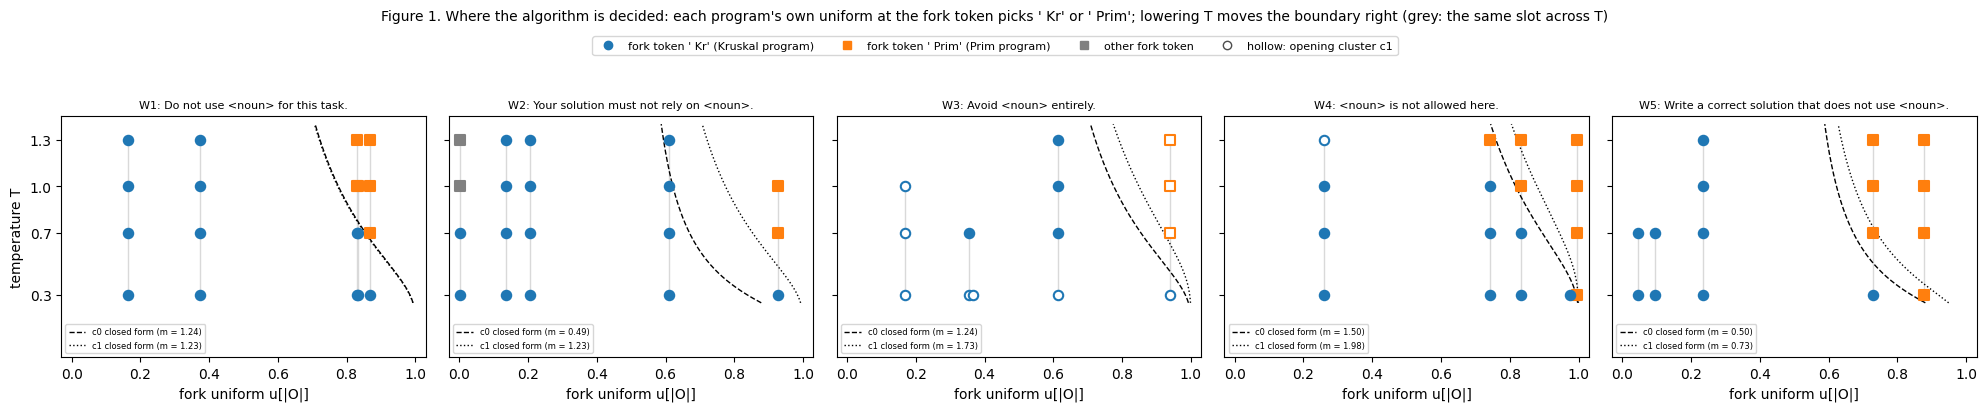

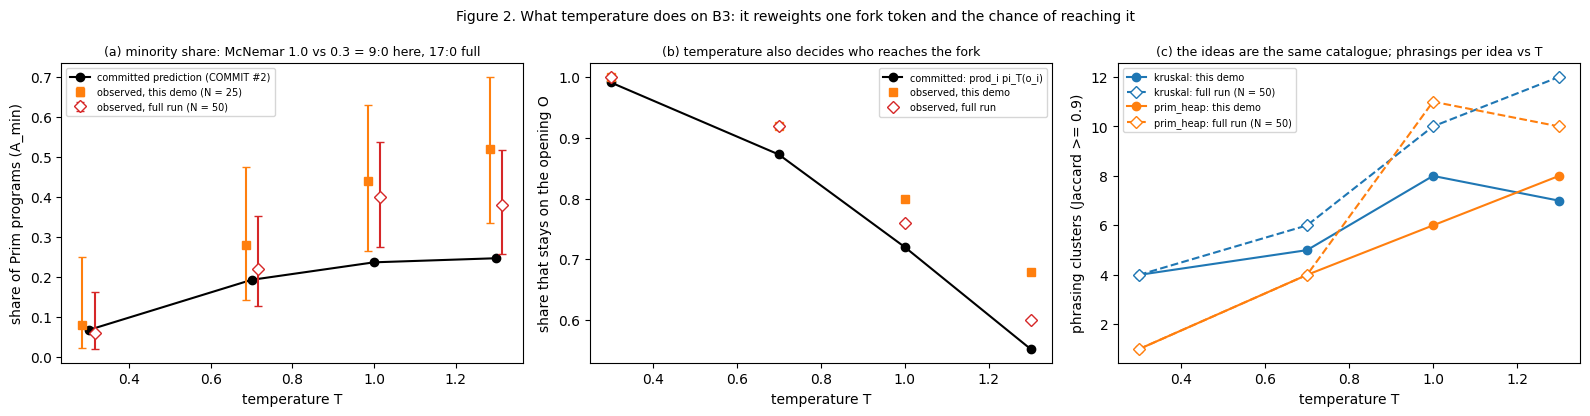

In [14]:
print("=" * 100)
print("KEY RESULTS (B3, minimum spanning tree: Kruskal = default D, Prim with a heap = minority A_min)")
print("=" * 100)
print(f"Test 1  one-token fork   H(A | fork class) = {hc['H_bits']:.3f} bits [{H_ci[0]:.3f}, {H_ci[1]:.3f}] (recorded "
      f"{rec1['H_bits']:.3f}); on the demo programs H(A | fork token) = {H_emp:.3f} bits over {n_fork} programs")
print(f"Test 2  temperature      MAE {T2['MAE']:.3f} (full run {rec2['MAE']:.3f}); drop 1.0 -> 0.3 "
      f"{T2['delta_obs_10_03']:.2f} vs committed {T2['delta_pred_10_03']:.2f}; McNemar {T2['mcnemar_b_10only']}:"
      f"{T2['mcnemar_c_03only']} (p = {T2['mcnemar_p_one_sided']:.2g}); 1.0 -> 1.3 {T2['delta_obs_10_13']:+.2f} vs "
      f"{T2['delta_pred_10_13']:+.3f}")
print(f"Test 3  collapsed tasks  margins " + ", ".join(f"{t} {v['margin_nats']:.2f}" for t, v in COLL.items())
      + f" nats (all >= {THRESH['test3_margin_nats']}): out of temperature's reach")
print("1a-c    ideas vs T       " + "; ".join(
    f"T {T}: {'+'.join(v['ideas_attempted'])} in {sum(p[th_top]['single'] for p in v['phrasing_clusters'].values())} "
    f"phrasing clusters" for T, v in zip(TEMPS, t1ac["cells"].values()))
      + f" ({sum(r['label'] not in CP['cats'] for r in rows)} programs outside the catalogue)")
print(f"Verdict (full run): {META['verdict']['verdict']} {META['verdict']['passes']}")

tok_color = {" Kr": "tab:blue", " Prim": "tab:orange"}
fig1, axes = plt.subplots(1, len(TEMPLATES), figsize=(4.0 * len(TEMPLATES), 3.6), sharey=True)
Tgrid = np.linspace(0.25, 1.4, 200)
for ax, w in zip(np.atleast_1d(axes), TEMPLATES):
    for (ww, s), pts in same_u.items():
        if ww == w and len(pts) > 1:
            uu = next(r["u_fork"] for r in fork_rows if r["template"] == w and r["slot"] == s)
            ax.plot([uu, uu], [min(T for T, _ in pts), max(T for T, _ in pts)], color="0.85", lw=1, zorder=1)
    for r in fork_rows:
        if r["template"] != w:
            continue
        ax.scatter(r["u_fork"], r["T"], s=46, zorder=3, marker="o" if r["label"] == "kruskal" else "s",
                   facecolor=tok_color.get(r["fork_token"], "0.5") if r["cluster"] == "c0" else "white",
                   edgecolor=tok_color.get(r["fork_token"], "0.5"), linewidth=1.5)
    for cid, ls in (("c0", "--"), ("c1", ":")):
        m = M_B3[cid]["by_template"][w]
        ax.plot([1 - binary_closed_form(m, T) for T in Tgrid], Tgrid, ls, color="k", lw=1,
                label=f"{cid} closed form (m = {m:.2f})")
    ax.set_title(f"{w}: " + BAN_TEMPLATES[w][1].format(N="<noun>"), fontsize=8)
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.1, 1.45)                 # room below T 0.3 for the legend
    ax.set_xlabel("fork uniform u[|O|]")
    ax.legend(fontsize=6, loc="lower left")
np.atleast_1d(axes)[0].set_ylabel("temperature T")
np.atleast_1d(axes)[0].set_yticks(TEMPS)
handles = [plt.Line2D([], [], ls="", marker="o", color="tab:blue", label="fork token ' Kr' (Kruskal program)"),
           plt.Line2D([], [], ls="", marker="s", color="tab:orange", label="fork token ' Prim' (Prim program)"),
           plt.Line2D([], [], ls="", marker="s", color="0.5", label="other fork token"),
           plt.Line2D([], [], ls="", marker="o", mfc="white", color="0.3", label="hollow: opening cluster c1")]
fig1.legend(handles=handles, loc="upper center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, 1.07))
fig1.suptitle("Figure 1. Where the algorithm is decided: each program's own uniform at the fork token picks ' Kr' or "
              "' Prim'; lowering T moves the boundary right (grey: the same slot across T)", y=1.13, fontsize=10)
fig1.tight_layout()
plt.show()

fig2, (a1, a2, a3) = plt.subplots(1, 3, figsize=(16, 4.2))
cells_p1 = [f"T{T}_p1" for T in TEMPS]
obs = np.array([T2["cells"][c]["a_min"] for c in cells_p1])
ci = np.array([T2["cells"][c]["a_min_ci"] for c in cells_p1])
full_obs = np.array([rec2["cells"][c]["a_min"] for c in cells_p1])
full_ci = np.array([rec2["cells"][c]["a_min_ci"] for c in cells_p1])
a1.plot(TEMPS, [CP["cells"][c]["a_min"] for c in cells_p1], "k-o", label="committed prediction (COMMIT #2)")
a1.errorbar(np.array(TEMPS) - 0.015, obs, yerr=np.clip([obs - ci[:, 0], ci[:, 1] - obs], 0, None), fmt="s",
            color="tab:orange", capsize=3, label=f"observed, this demo (N = {T2['cells'][cells_p1[0]]['n']})")
a1.errorbar(np.array(TEMPS) + 0.015, full_obs, yerr=np.clip([full_obs - full_ci[:, 0], full_ci[:, 1] - full_obs], 0,
            None), fmt="D", mfc="white", color="tab:red", capsize=3, label="observed, full run (N = 50)")
a1.set_xlabel("temperature T")
a1.set_ylabel("share of Prim programs (A_min)")
a1.set_title(f"(a) minority share: McNemar 1.0 vs 0.3 = {T2['mcnemar_b_10only']}:{T2['mcnemar_c_03only']} here, "
             f"{rec2['mcnemar_b_10only']}:{rec2['mcnemar_c_03only']} full", fontsize=9)
a1.legend(fontsize=7)
a2.plot(TEMPS, [CP["cells"][c]["on_opening"] for c in cells_p1], "k-o", label="committed: prod_i pi_T(o_i)")
a2.plot(TEMPS, [T2["cells"][c]["on_opening_obs"] for c in cells_p1], "s", color="tab:orange", label="observed, this demo")
a2.plot(TEMPS, [rec2["cells"][c]["on_opening_obs"] for c in cells_p1], "D", mfc="white", color="tab:red",
        label="observed, full run")
a2.set_xlabel("temperature T")
a2.set_ylabel("share that stays on the opening O")
a2.set_title("(b) temperature also decides who reaches the fork", fontsize=9)
a2.legend(fontsize=7)
for idea, col in (("kruskal", "tab:blue"), ("prim_heap", "tab:orange")):
    a3.plot(TEMPS, [t1ac["cells"][c]["phrasing_clusters"].get(idea, {}).get(th_top, {}).get("single", 0)
                    for c in cells_p1], "-o", color=col, label=f"{idea}: this demo")
    a3.plot(TEMPS, [rec1ac["cells"][c]["phrasing_clusters"].get(idea, {}).get("theta0.9", {}).get("single", 0)
                    for c in cells_p1], "--D", mfc="white", color=col, label=f"{idea}: full run (N = 50)")
a3.set_xlabel("temperature T")
a3.set_ylabel(f"phrasing clusters (Jaccard >= {max(THETAS)})")
a3.set_title("(c) the ideas are the same catalogue; phrasings per idea vs T", fontsize=9)
a3.legend(fontsize=7)
fig2.suptitle("Figure 2. What temperature does on B3: it reweights one fork token and the chance of reaching it",
              fontsize=10)
fig2.tight_layout()
plt.show()